# Equity Lens: performance, risk and prediction validation

**Analytical question:** Which selected technology stocks outperformed SPY during 2021?2025, what risk accompanied those returns, and can a lagged-return model beat a naive forecast?

This notebook runs entirely on the bundled **real historical snapshot**. The universe is hand-picked and contains surviving companies. Results are descriptive, not causal or prospective investment claims.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.data import load_snapshot, close_matrix
from src.analytics import summary_metrics, daily_returns, drawdowns, monthly_returns, insight_bullets
from src.modeling import walk_forward
from src.sql_analysis import monthly_sql_summary
plt.rcParams.update({"figure.figsize": (12, 5), "axes.spines.top": False, "axes.spines.right": False})

## 1. Inspect and validate inputs
The pipeline enforces a Date/Ticker key and positive, finite, consistent OHLC bars with nonnegative volume. It reports duplicate removal and never fills missing prices. The provenance manifest records the source, adjustment policy, retrieval time and SHA-256.

In [2]:
import json, hashlib
from src.data import SNAPSHOT
manifest = json.loads(SNAPSHOT.with_suffix(".json").read_text())
assert hashlib.sha256(SNAPSHOT.read_bytes()).hexdigest() == manifest["sha256"]
prices, audit = load_snapshot()
display(audit)
display(prices.groupby("Ticker").agg(First=("Date", "min"), Last=("Date", "max"), Rows=("Date", "size")))
print("Provider:", manifest["provider"], "| retrieved:", manifest["retrieved_at_utc"])
print("Validated rows:", len(prices))

,Check,Rows
0,Input rows,7530
1,Invalid date / ticker,0
2,Missing / non-finite numeric fields,0
3,Nonpositive price / negative volume,0
4,Inconsistent OHLC bar,0
5,Invalid rows removed (unique),0
6,Duplicate keys removed,0
7,Output rows,7530


,First,Last,Rows
Ticker,,,
AAPL,2021-01-04,2025-12-31,1255
AMZN,2021-01-04,2025-12-31,1255
GOOGL,2021-01-04,2025-12-31,1255
MSFT,2021-01-04,2025-12-31,1255
NVDA,2021-01-04,2025-12-31,1255
SPY,2021-01-04,2025-12-31,1255


Provider: Yahoo Finance via yfinance | retrieved: 2026-10-20T16:29:21.651364+00:00
Validated rows: 7530


## 2. Compare on common sessions
Normalize each adjusted series to $100. Raw share prices alone do not compare company performance. The selected observations run from the first through the last common date; returns exclude the first session because its preceding close is outside the sample.

Common observations: 1,255; excluded dates: 0


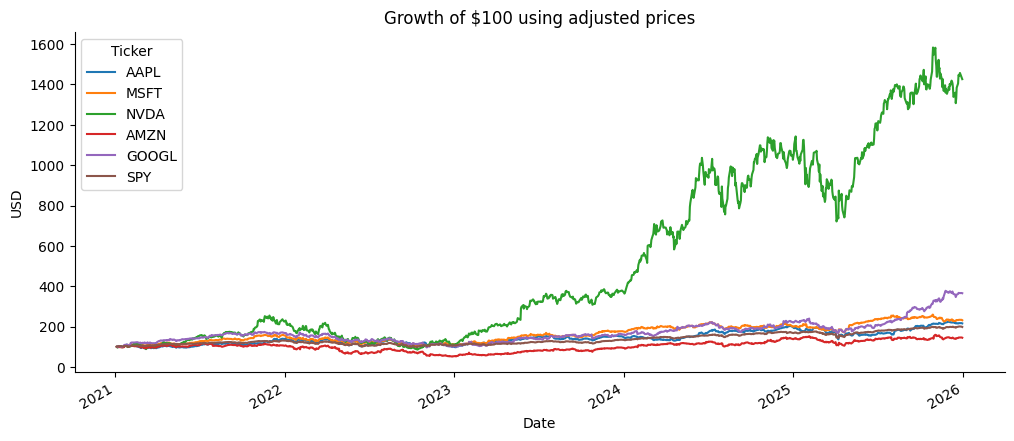

,Total return,CAGR,Annual volatility,Max drawdown,Sharpe ratio,Beta vs benchmark,Correlation vs benchmark,Daily VaR 95% (loss),Daily ES 95% (loss),Positive days
Ticker,,,,,,,,,,
AAPL,1.1581,0.1667,0.2786,-0.3336,0.6935,1.2347,0.7582,0.0280,0.0389,0.5303
MSFT,1.3153,0.1833,0.2571,-0.3715,0.7845,1.1398,0.7585,0.0264,0.0355,0.5239
NVDA,13.2620,0.7036,0.5222,-0.6634,1.2820,2.1332,0.6989,0.0483,0.0675,0.5359
AMZN,0.4487,0.0771,0.3511,-0.5615,0.3875,1.4678,0.7154,0.0323,0.0496,0.5159
GOOGL,2.6540,0.2966,0.3115,-0.4432,0.9919,1.2520,0.6879,0.0294,0.0430,0.5399
SPY,0.9808,0.1469,0.1711,-0.2450,0.8883,1.0000,1.0000,0.0166,0.0248,0.5470


In [3]:
symbols = ["AAPL", "MSFT", "NVDA", "AMZN", "GOOGL", "SPY"]
close, excluded_dates = close_matrix(prices, symbols)
print(f"Common observations: {len(close):,}; excluded dates: {excluded_dates}")
ax = close.div(close.iloc[0]).mul(100).plot(title="Growth of $100 using adjusted prices")
ax.set_ylabel("USD")
plt.show()
metrics = summary_metrics(close)
display(metrics.round(4))

## 3. Explain the risk behind the return
CAGR uses elapsed calendar time; volatility is sample daily standard deviation times sqrt(252). Drawdown is relative to the running peak inside this window. Correlation is computed on daily returns. Sharpe assumes a constant 0% annual risk-free rate.

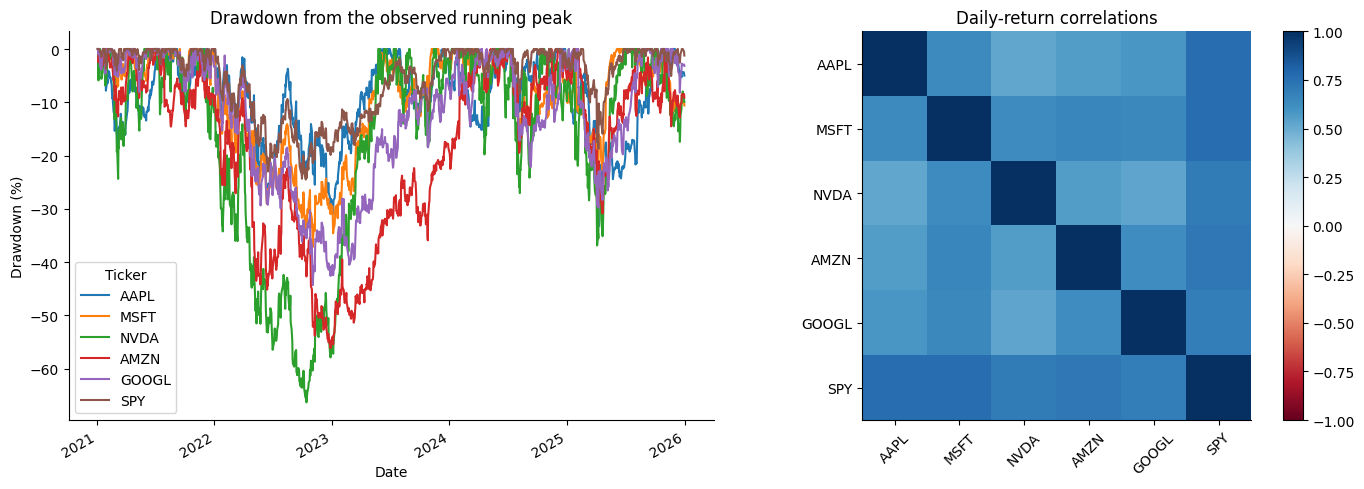

Ticker,AAPL,MSFT,NVDA,AMZN,GOOGL,SPY
Date,,,,,,
2025-01-31,-0.0576,-0.0153,-0.1059,0.0834,0.0778,0.0269
2025-02-28,0.0259,-0.0416,0.0404,-0.1069,-0.1654,-0.0127
2025-03-31,-0.0815,-0.0544,-0.1323,-0.1037,-0.0908,-0.0557
2025-04-30,-0.0434,0.0529,0.0050,-0.0307,0.0269,-0.0087
2025-05-31,-0.0536,0.1668,0.2406,0.1116,0.0815,0.0628
2025-06-30,0.0215,0.0805,0.1693,0.0701,0.0274,0.0514
2025-07-31,0.0117,0.0726,0.1258,0.0671,0.0889,0.0230
2025-08-31,0.1196,-0.0487,-0.0207,-0.0218,0.1095,0.0205
2025-09-30,0.0969,0.0222,0.0713,-0.0412,0.1428,0.0356


NVDA had the highest selected-stock return (1326.2%); SPY returned 98.1% over the same sessions.
NVDA had the highest selected-stock annualized volatility (52.2%) and a maximum drawdown of -66.3%.
These are historical comparisons of a hand-picked group of surviving large-cap companies; they do not establish future performance or causation.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
drawdowns(close).mul(100).plot(ax=axes[0], title="Drawdown from the observed running peak")
axes[0].set_ylabel("Drawdown (%)")
correlation = daily_returns(close).corr()
im = axes[1].imshow(correlation, vmin=-1, vmax=1, cmap="RdBu")
axes[1].set_xticks(range(len(symbols)), symbols, rotation=45)
axes[1].set_yticks(range(len(symbols)), symbols)
axes[1].set_title("Daily-return correlations")
fig.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.show()
display(monthly_returns(close).tail(12).round(4))
for insight in insight_bullets(close):
    print(insight)

## 4. Reproduce daily-return summaries in SQL
`LAG` is partitioned by ticker and ordered by date. The monthly aggregation reports the **mean daily return**, not a compounded monthly return. The first record per symbol has no in-sample previous close.

In [5]:
query = (ROOT / "sql" / "analysis.sql").read_text()
print(query)
sql_result = monthly_sql_summary(prices)
display(sql_result.head(12))
aapl = prices[prices.Ticker == "AAPL"].set_index("Date").Close.pct_change().dropna()
pandas_monthly_mean = aapl.groupby(aapl.index.strftime("%Y-%m")).mean()
sql_monthly_mean = sql_result[sql_result.Ticker == "AAPL"].set_index("Month").mean_daily_return
np.testing.assert_allclose(pandas_monthly_mean, sql_monthly_mean)
print("SQL/Pandas monthly daily-return means agree.")

-- Run against the validated `prices` table using SQLite.
-- LAG partitions by ticker so one stock never inherits another stock's price.
WITH lagged AS (
    SELECT Date, Ticker, Close, Volume,
           LAG(Close) OVER (PARTITION BY Ticker ORDER BY Date) AS previous_close
    FROM prices
), daily AS (
    SELECT *, Close / previous_close - 1.0 AS daily_return
    FROM lagged
)
SELECT Ticker,
       SUBSTR(Date, 1, 7) AS Month,
       COUNT(daily_return) AS return_observations,
       AVG(daily_return) AS mean_daily_return,
       MIN(daily_return) AS worst_day,
       MAX(daily_return) AS best_day,
       AVG(Volume) AS mean_daily_volume
FROM daily
GROUP BY Ticker, SUBSTR(Date, 1, 7)
ORDER BY Ticker, Month;




,Ticker,Month,return_observations,mean_daily_return,worst_day,best_day,mean_daily_volume
0,AAPL,2021-01,18,0.001359,-0.037421,0.036659,1.179085e+08
1,AAPL,2021-02,19,-0.004269,-0.034783,0.025758,9.651872e+07
2,AAPL,2021-03,23,0.000574,-0.041674,0.053851,1.152356e+08
3,AAPL,2021-04,21,0.003591,-0.017853,0.024307,8.999321e+07
4,AAPL,2021-05,20,-0.002470,-0.035385,0.021012,8.559674e+07
5,AAPL,2021-06,22,0.004349,-0.012154,0.024578,7.302682e+07
6,AAPL,2021-07,21,0.003096,-0.026914,0.025974,9.138262e+07
7,AAPL,2021-08,22,0.001957,-0.025501,0.030417,6.643376e+07
8,AAPL,2021-09,21,-0.003267,-0.033102,0.016872,8.561120e+07
9,AAPL,2021-10,21,0.002785,-0.024605,0.024992,7.452758e+07


SQL/Pandas monthly daily-return means agree.


## 5. Test prediction value rather than visual fit
Predict each session's return using only previous-session information: 20 lagged returns, lagged 5/20-session means and lagged 20-session volatility. A fresh scaler and Ridge(alpha=10) are fitted within each of four expanding chronological folds. The first training window uses 60% of complete feature rows. Compare against zero return (previous close) and training mean return.

The model stays fixed within each test block; features update with observed history each day. This is a series of one-step predictions, not a multi-day forecast. Hyperparameters are fixed, and no tuning on these test results is performed.

,MAE (USD),RMSE (USD),Return MAE (bps),Direction accuracy,Observations,MAE improvement vs naive
Model,,,,,,
Previous close,2.4834,3.6664,116.0847,NaN,494,0.0000
Historical mean,2.4722,3.6648,115.5573,0.5497,494,0.0045
Ridge regression,2.5405,3.7158,118.8787,0.4807,494,-0.0230


,Fold,Model,Train end,Test start,Test end,Train rows,Test rows,Return MAE (bps)
0,1,Previous close,2024-01-11,2024-01-12,2024-07-10,740,123,112.647637
1,1,Historical mean,2024-01-11,2024-01-12,2024-07-10,740,123,112.175150
2,1,Ridge regression,2024-01-11,2024-01-12,2024-07-10,740,123,117.342138
3,2,Previous close,2024-07-10,2024-07-11,2025-01-06,863,124,95.595924
4,2,Historical mean,2024-07-10,2024-07-11,2025-01-06,863,124,94.450915
5,2,Ridge regression,2024-07-10,2024-07-11,2025-01-06,863,124,96.512464
6,3,Previous close,2025-01-06,2025-01-07,2025-07-07,987,123,164.692431
7,3,Historical mean,2025-01-06,2025-01-07,2025-07-07,987,123,164.565576
8,3,Ridge regression,2025-01-06,2025-01-07,2025-07-07,987,123,169.025456
9,4,Previous close,2025-07-07,2025-07-08,2025-12-31,1110,124,91.766955


Ridge MAE improvement versus previous close: -2.30%


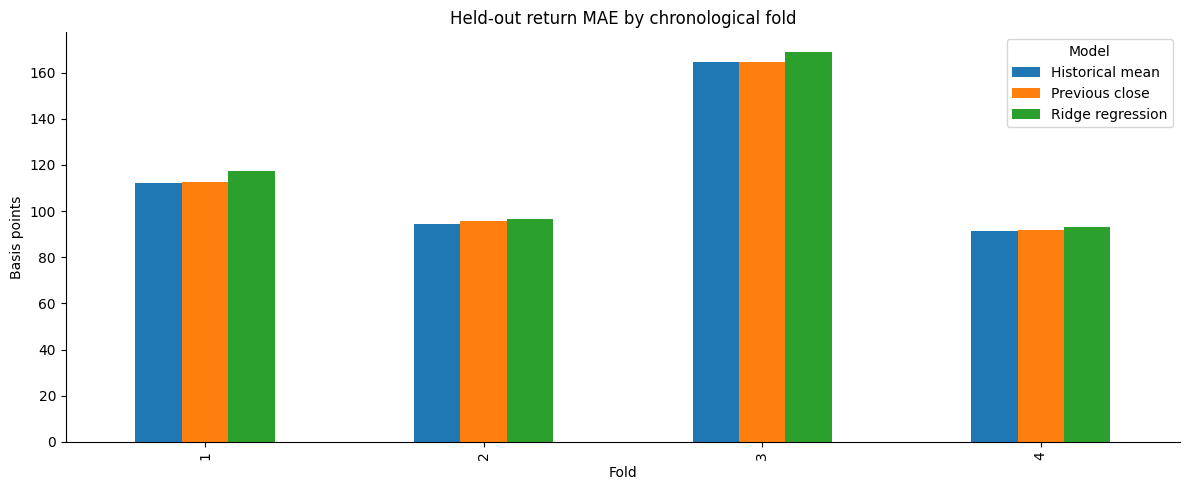

In [6]:
scores, predictions, folds = walk_forward(close["AAPL"])
display(scores.round(4))
display(folds[["Fold", "Model", "Train end", "Test start", "Test end", "Train rows", "Test rows", "Return MAE (bps)"]])
assert (folds["Train end"] < folds["Test start"]).all()
assert not predictions.duplicated(["Date", "Model"]).any()
change = scores.loc["Ridge regression", "MAE improvement vs naive"]
print(f"Ridge MAE improvement versus previous close: {change:+.2%}")
folds.pivot(index="Fold", columns="Model", values="Return MAE (bps)").plot.bar(title="Held-out return MAE by chronological fold")
plt.ylabel("Basis points")
plt.tight_layout()
plt.show()

## 6. Interpret and communicate
The highest historical return need not imply a comfortable investment path. Pair it with volatility and drawdown. On the bundled Apple experiment, Ridge increases price MAE by about 2.30% versus the previous-close baseline. This negative result is useful evidence: complexity alone did not improve prediction.

**Limits:** selected survivors, one historical period, revised adjusted prices, no point-in-time fundamentals, no exchange-calendar completeness audit, no transaction costs or strategy backtest. Further experiments require a predeclared broader universe and a fresh validation period.

**Deliverable:** run `python -m scripts.build_report` from the project root to reproduce the Markdown findings, figure, quality audit, SQL summaries, model scores and dated predictions.